In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import loguniform
 
from sklearn.datasets import load_breast_cancer, make_classification
from sklearn.model_selection import (train_test_split, cross_val_score, cross_validate,
                                     validation_curve, StratifiedKFold, KFold,
                                     GridSearchCV, RandomizedSearchCV)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder, OrdinalEncoder
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
 
RS = 42
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)
 

=== 1. OVER/UNDERFITTING ===
max_depth= 1  train=0.762  cv=0.757  gap=0.005
max_depth= 2  train=0.804  cv=0.772  gap=0.032
max_depth= 3  train=0.830  cv=0.777  gap=0.053
max_depth= 5  train=0.907  cv=0.793  gap=0.113
max_depth= 8  train=0.979  cv=0.762  gap=0.217
max_depth=12  train=0.999  cv=0.763  gap=0.236
max_depth=20  train=1.000  cv=0.767  gap=0.233
Best depth by CV: 5


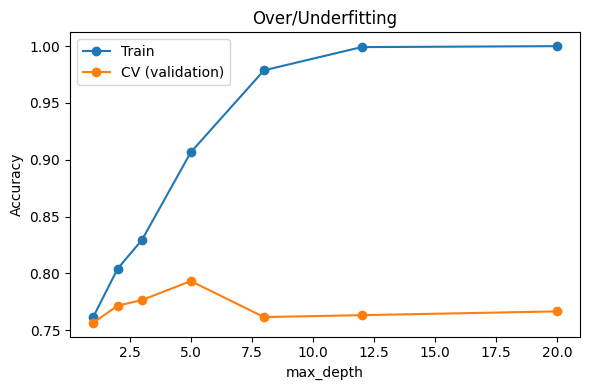

In [2]:
print("=== 1. OVER/UNDERFITTING ===")
Xn, yn = make_classification(n_samples=600, n_features=20, n_informative=5,
                             flip_y=0.1, random_state=RS)   # flip_y = thora noise
depths = [1, 2, 3, 5, 8, 12, 20]
train_sc, val_sc = validation_curve(
    DecisionTreeClassifier(random_state=RS), Xn, yn,
    param_name="max_depth", param_range=depths, cv=cv5)
for d, tr, va in zip(depths, train_sc.mean(axis=1), val_sc.mean(axis=1)):
    print(f"max_depth={d:>2}  train={tr:.3f}  cv={va:.3f}  gap={tr - va:.3f}")
best_d = depths[int(val_sc.mean(axis=1).argmax())]
print("Best depth by CV:", best_d)
 
plt.figure(figsize=(6, 4))
plt.plot(depths, train_sc.mean(axis=1), "o-", label="Train")
plt.plot(depths, val_sc.mean(axis=1), "o-", label="CV (validation)")
plt.xlabel("max_depth"); plt.ylabel("Accuracy"); plt.title("Over/Underfitting")
plt.legend(); plt.tight_layout(); plt.show()

In [3]:
print("\n=== 2. SCALING ===")
X, y = load_breast_cancer(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RS, stratify=y)
 
setups = {
    "KNN  no scaling":  KNeighborsClassifier(),
    "KNN  Standard":    Pipeline([("s", StandardScaler()), ("m", KNeighborsClassifier())]),
    "KNN  MinMax":      Pipeline([("s", MinMaxScaler()), ("m", KNeighborsClassifier())]),
    "SVC  no scaling":  SVC(),
    "SVC  Standard":    Pipeline([("s", StandardScaler()), ("m", SVC())]),
    "Tree no scaling":  DecisionTreeClassifier(random_state=RS),
    "Tree Standard":    Pipeline([("s", StandardScaler()), ("m", DecisionTreeClassifier(random_state=RS))]),
}
for name, m in setups.items():
    s = cross_val_score(m, X, y, cv=cv5)
    print(f"{name:<17} mean={s.mean():.3f} std={s.std():.3f}")


=== 2. SCALING ===
KNN  no scaling   mean=0.935 std=0.020
KNN  Standard     mean=0.963 std=0.018
KNN  MinMax       mean=0.963 std=0.020
SVC  no scaling   mean=0.914 std=0.024
SVC  Standard     mean=0.977 std=0.016
Tree no scaling   mean=0.910 std=0.028
Tree Standard     mean=0.910 std=0.028


In [4]:
print("\n=== 3. ENCODING ===")
rng = np.random.RandomState(RS)
n = 300
df = pd.DataFrame({
    "city": rng.choice(["Lahore", "Karachi", "Islamabad"], n),
    "size": rng.choice(["small", "medium", "large"], n),
    "area": rng.uniform(500, 3000, n),
})
city_eff = df["city"].map({"Lahore": 0, "Karachi": 5, "Islamabad": 15})
size_eff = df["size"].map({"small": 0, "medium": 8, "large": 20})
df["price"] = 0.04 * df["area"] + city_eff + size_eff + rng.normal(0, 3, n)
 
Xh, yh = df.drop(columns="price"), df["price"]
print(df.head(3))
 
pre = ColumnTransformer([
    ("city", OneHotEncoder(handle_unknown="ignore"), ["city"]),
    ("size", OrdinalEncoder(categories=[["small", "medium", "large"]]), ["size"]),
    ("area", StandardScaler(), ["area"]),
])
reg = Pipeline([("pre", pre), ("lr", LinearRegression())])
r2 = cross_val_score(reg, Xh, yh, cv=KFold(5, shuffle=True, random_state=RS), scoring="r2")
print("Pipeline (OneHot + Ordinal + Scaler) CV R2: %.3f" % r2.mean())
 
reg.fit(Xh, yh)
print("Encoded feature names:", list(reg.named_steps["pre"].get_feature_names_out()))


=== 3. ENCODING ===
        city   size         area       price
0  Islamabad  large  2380.936324  130.746641
1     Lahore  small  2478.947609   99.426086
2  Islamabad  small  2474.045357  115.425947
Pipeline (OneHot + Ordinal + Scaler) CV R2: 0.990
Encoded feature names: ['city__city_Islamabad', 'city__city_Karachi', 'city__city_Lahore', 'size__size', 'area__area']


In [5]:
print("\n=== 4. GridSearchCV ===")
pipe = Pipeline([("sc", StandardScaler()), ("clf", SVC())])
param_grid = {
    "clf__C": [0.1, 1, 10, 100],
    "clf__gamma": ["scale", 0.01, 0.001],
    "clf__kernel": ["rbf", "linear"],
}
t0 = time.time()
grid = GridSearchCV(pipe, param_grid, cv=cv5, scoring="f1", n_jobs=-1)
grid.fit(X_train, y_train)               # sirf TRAIN pe search
print("Combinations:", len(grid.cv_results_["params"]),
      "| time: %.1fs" % (time.time() - t0))
print("Best params :", grid.best_params_)
print("Best CV f1  : %.3f" % grid.best_score_)
print("Test accuracy (final, sirf ek baar): %.3f" % grid.score(X_test, y_test))


=== 4. GridSearchCV ===
Combinations: 24 | time: 7.1s
Best params : {'clf__C': 0.1, 'clf__gamma': 'scale', 'clf__kernel': 'linear'}
Best CV f1  : 0.981
Test accuracy (final, sirf ek baar): 0.986


In [6]:
print("\n=== 5. RandomizedSearchCV ===")
param_dist = {
    "clf__C": loguniform(1e-2, 1e3),
    "clf__gamma": loguniform(1e-4, 1e0),
    "clf__kernel": ["rbf", "linear"],
}
t0 = time.time()
rand = RandomizedSearchCV(pipe, param_dist, n_iter=20, cv=cv5, scoring="f1",
                          random_state=RS, n_jobs=-1)
rand.fit(X_train, y_train)
print("Tried: 20 random combos | time: %.1fs" % (time.time() - t0))
print("Best params :", {k: (round(float(v), 4) if isinstance(v, float) else v)
                        for k, v in rand.best_params_.items()})
print("Best CV f1  : %.3f" % rand.best_score_)
print("Test accuracy: %.3f" % rand.score(X_test, y_test))


=== 5. RandomizedSearchCV ===
Tried: 20 random combos | time: 0.4s
Best params : {'clf__C': 0.0736, 'clf__gamma': 0.0037, 'clf__kernel': 'linear'}
Best CV f1  : 0.984
Test accuracy: 0.986


In [7]:
print("\n=== 6. MODEL COMPARISON ===")
models = {
    "LogReg":       Pipeline([("s", StandardScaler()), ("m", LogisticRegression(max_iter=1000))]),
    "KNN":          Pipeline([("s", StandardScaler()), ("m", KNeighborsClassifier())]),
    "SVC":          Pipeline([("s", StandardScaler()), ("m", SVC())]),
    "DecisionTree": DecisionTreeClassifier(max_depth=4, random_state=RS),
    "RandomForest": RandomForestClassifier(n_estimators=200, random_state=RS),
}
rows = []
for name, m in models.items():
    t0 = time.time()
    r = cross_validate(m, X_train, y_train, cv=cv5,
                       scoring=["accuracy", "f1", "roc_auc"])
    rows.append({"model": name,
                 "acc": r["test_accuracy"].mean(),
                 "f1": r["test_f1"].mean(),
                 "f1_std": r["test_f1"].std(),
                 "auc": r["test_roc_auc"].mean(),
                 "time_s": time.time() - t0})
table = pd.DataFrame(rows).sort_values("f1", ascending=False).round(3)
print(table.to_string(index=False))
 
winner = table.iloc[0]["model"]
print("\nWinner by CV f1:", winner)
final = models[winner].fit(X_train, y_train)
print(classification_report(y_test, final.predict(X_test),
                            target_names=load_breast_cancer().target_names))


=== 6. MODEL COMPARISON ===
       model   acc    f1  f1_std   auc  time_s
      LogReg 0.978 0.983   0.008 0.996   0.073
         SVC 0.969 0.976   0.011 0.996   0.098
         KNN 0.963 0.970   0.009 0.988   0.069
RandomForest 0.963 0.970   0.015 0.989   2.362
DecisionTree 0.930 0.944   0.012 0.927   0.057

Winner by CV f1: LogReg
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

